In [1]:
%pip -q install rdkit pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 76.5 MB/s eta 0:00:00


,Fragment_ID,Fragment_name,Attachment_SMILES
0,F01,Fluoro,[*:1]F
1,F02,Chloro,[*:1]Cl
2,F03,Bromo,[*:1]Br
3,F04,Methyl,[*:1]C
4,F05,Ethyl,[*:1]CC
5,F06,Isopropyl,[*:1]C(C)C
6,F07,Cyclopropyl,[*:1]C1CC1
7,F08,Trifluoromethyl,[*:1]C(F)(F)F
8,F09,Hydroxy,[*:1]O
9,F10,Methoxy,[*:1]OC


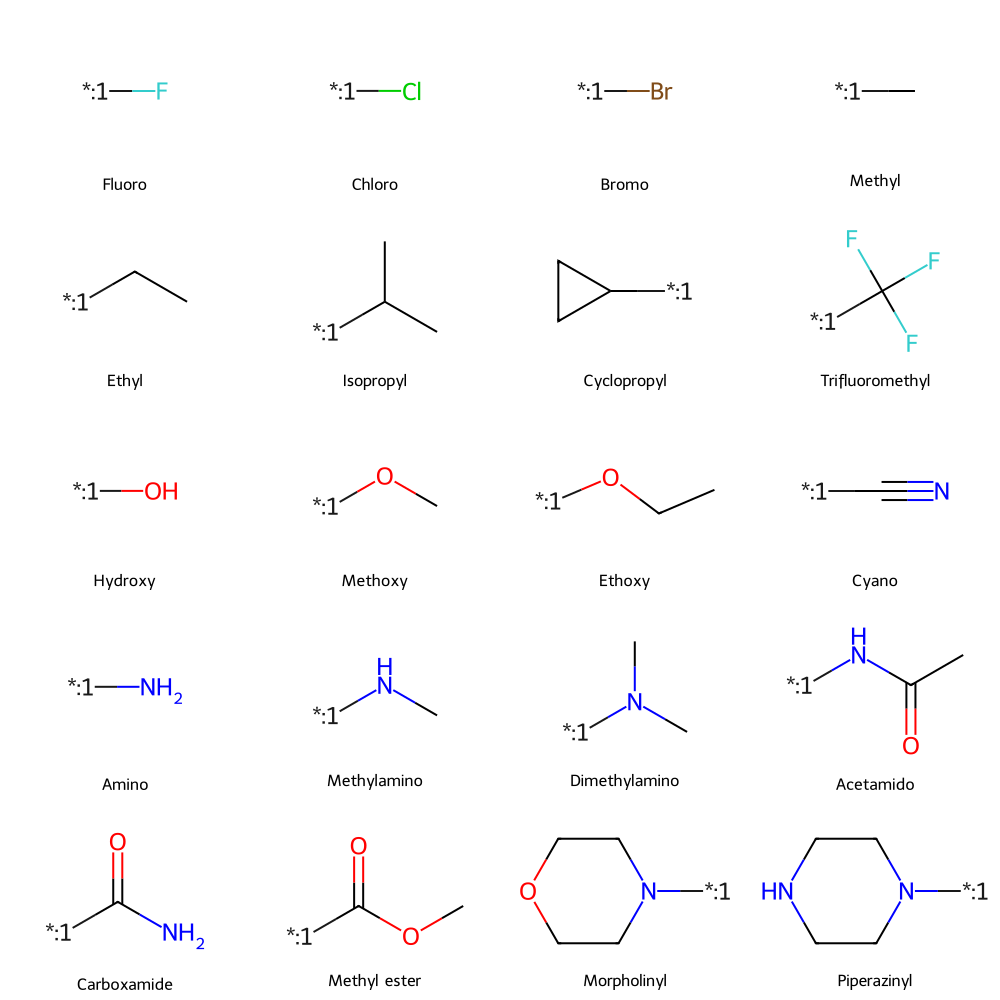

Site and fragment input checks: PASS
Planned single substitutions: 160
Planned double substitutions: 11200
Total enumeration attempts: 11360


In [2]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display

PARENT_SMILES = "O=C1c2ccccc2-n2c1nc1ccccc1c2=O"
parent = Chem.MolFromSmiles(PARENT_SMILES)

assert parent is not None
assert Chem.MolToInchiKey(parent) == \
    "VQQVWGVXDIPORV-UHFFFAOYSA-N"

# Indices apply ONLY to the exact parent SMILES above.
sites = {
    "C-1": 15, "C-2": 14, "C-3": 13, "C-4": 12,
    "C-7": 3, "C-8": 4, "C-9": 5, "C-10": 6
}

# [*:1] explicitly marks the point attached to the scaffold.
# These are exploratory design fragments, not approved synthetic routes.
fragment_rows = [
    ("F01", "Fluoro",          "[*:1]F"),
    ("F02", "Chloro",          "[*:1]Cl"),
    ("F03", "Bromo",           "[*:1]Br"),
    ("F04", "Methyl",          "[*:1]C"),
    ("F05", "Ethyl",           "[*:1]CC"),
    ("F06", "Isopropyl",       "[*:1]C(C)C"),
    ("F07", "Cyclopropyl",     "[*:1]C1CC1"),
    ("F08", "Trifluoromethyl", "[*:1]C(F)(F)F"),
    ("F09", "Hydroxy",         "[*:1]O"),
    ("F10", "Methoxy",         "[*:1]OC"),
    ("F11", "Ethoxy",          "[*:1]OCC"),
    ("F12", "Cyano",           "[*:1]C#N"),
    ("F13", "Amino",           "[*:1]N"),
    ("F14", "Methylamino",     "[*:1]NC"),
    ("F15", "Dimethylamino",   "[*:1]N(C)C"),
    ("F16", "Acetamido",       "[*:1]NC(=O)C"),
    ("F17", "Carboxamide",     "[*:1]C(=O)N"),
    ("F18", "Methyl ester",    "[*:1]C(=O)OC"),
    ("F19", "Morpholinyl",     "[*:1]N1CCOCC1"),
    ("F20", "Piperazinyl",     "[*:1]N1CCNCC1"),
]

catalogue = pd.DataFrame(
    fragment_rows,
    columns=["Fragment_ID", "Fragment_name", "Attachment_SMILES"]
)

fragment_molecules = []

for row in catalogue.itertuples():
    mol = Chem.MolFromSmiles(row.Attachment_SMILES)
    assert mol is not None, row.Fragment_ID

    dummy_atoms = [
        atom for atom in mol.GetAtoms()
        if atom.GetAtomicNum() == 0
    ]
    assert len(dummy_atoms) == 1, row.Fragment_ID
    assert dummy_atoms[0].GetAtomMapNum() == 1
    assert dummy_atoms[0].GetDegree() == 1
    assert len(Chem.GetMolFrags(mol)) == 1

    fragment_molecules.append(mol)

for site_name, atom_index in sites.items():
    atom = parent.GetAtomWithIdx(atom_index)
    assert atom.GetSymbol() == "C", site_name
    assert atom.GetIsAromatic(), site_name
    assert atom.GetTotalNumHs() == 1, site_name

assert catalogue["Fragment_ID"].is_unique
assert catalogue["Attachment_SMILES"].is_unique

single_count = len(sites) * len(catalogue)
pair_count = (
    len(sites) * (len(sites) - 1) // 2
) * len(catalogue) ** 2

display(catalogue)
display(Draw.MolsToGridImage(
    fragment_molecules,
    legends=catalogue["Fragment_name"].tolist(),
    molsPerRow=4,
    subImgSize=(250, 200)
))

print("Site and fragment input checks: PASS")
print("Planned single substitutions:", single_count)
print("Planned double substitutions:", pair_count)
print("Total enumeration attempts:", single_count + pair_count)

In [3]:
import io
import json
import zipfile
import hashlib
import shutil
import sys
from itertools import combinations, product
from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
from rdkit import Chem, rdBase
from rdkit.Chem import Draw, rdMolDescriptors
from IPython.display import display
from google.colab import files

assert "catalogue" in globals() and "sites" in globals(), \
    "Run the fragment-catalogue cell first."

# ---------- Load the previous 96-structure library ----------
print("Upload the expanded 96-structure library ZIP.")
uploaded = files.upload()
zip_names = [n for n in uploaded if n.lower().endswith(".zip")]
assert len(zip_names) == 1, "Upload only the expanded-library ZIP."

with zipfile.ZipFile(io.BytesIO(uploaded[zip_names[0]])) as archive:
    previous = pd.read_csv(
        io.BytesIO(archive.read("tryptanthrin_analogs_clean.csv")),
        keep_default_na=False
    )
    previous_evidence = archive.read("reference_evidence.csv")

assert len(previous) == 96
assert previous["Analog_ID"].is_unique

def canonical(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError("SMILES parsing failed")
    Chem.SanitizeMol(mol)
    return Chem.MolToSmiles(mol, canonical=True)

previous["SMILES"] = previous["SMILES"].map(canonical)
assert previous["SMILES"].is_unique

old_records = previous.set_index("SMILES").to_dict("index")
id_owners = dict(zip(previous["Analog_ID"], previous["SMILES"]))

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
out = Path("broad_library_runs") / run_id
out.mkdir(parents=True, exist_ok=False)

catalogue.to_csv(out / "fragment_catalogue.csv", index=False)
pd.DataFrame(
    [{"Site": s, "Parent_atom_index": i} for s, i in sites.items()]
).to_csv(out / "modification_sites.csv", index=False)

(out / "reference_evidence.csv").write_bytes(previous_evidence)
(out / "previous_library_input.zip").write_bytes(uploaded[zip_names[0]])

parent = Chem.MolFromSmiles(PARENT_SMILES)
parent_smiles = canonical(PARENT_SMILES)
assert Chem.MolToInchiKey(parent) == \
    "VQQVWGVXDIPORV-UHFFFAOYSA-N"

fragment_lookup = catalogue.set_index("Fragment_ID").to_dict("index")

# ---------- Explicit attachment-point handling ----------
def attach_fragment(molecule, site_index, attachment_smiles):
    fragment = Chem.MolFromSmiles(attachment_smiles)
    if fragment is None:
        raise ValueError("Invalid fragment")

    dummy_indices = [
        a.GetIdx() for a in fragment.GetAtoms()
        if a.GetAtomicNum() == 0
    ]
    if len(dummy_indices) != 1:
        raise ValueError("Expected one attachment marker")

    dummy_index = dummy_indices[0]
    dummy = fragment.GetAtomWithIdx(dummy_index)
    if dummy.GetDegree() != 1:
        raise ValueError("Attachment marker must have one neighbor")

    neighbor_index = dummy.GetNeighbors()[0].GetIdx()
    attachment_bond = fragment.GetBondBetweenAtoms(
        dummy_index, neighbor_index
    )
    if attachment_bond.GetBondType() != Chem.BondType.SINGLE:
        raise ValueError("Expected a single attachment bond")

    # Remove the marker first, updating the neighboring atom's index.
    edit_fragment = Chem.RWMol(fragment)
    edit_fragment.RemoveAtom(dummy_index)
    if neighbor_index > dummy_index:
        neighbor_index -= 1

    prepared_fragment = edit_fragment.GetMol()
    offset = molecule.GetNumAtoms()

    editable = Chem.RWMol(
        Chem.CombineMols(molecule, prepared_fragment)
    )
    editable.AddBond(
        site_index,
        offset + neighbor_index,
        Chem.BondType.SINGLE
    )

    # Parent atoms remain first, so their indices remain stable.
    return editable.GetMol()

def validate(mol):
    Chem.SanitizeMol(mol)

    if any(a.GetAtomicNum() == 0 for a in mol.GetAtoms()):
        raise ValueError("Attachment marker remains")
    if any(a.GetNumRadicalElectrons() for a in mol.GetAtoms()):
        raise ValueError("Unexpected radical")
    if len(Chem.GetMolFrags(mol)) != 1:
        raise ValueError("Disconnected structure")
    if Chem.GetFormalCharge(mol) != 0:
        raise ValueError("Unexpected net formal charge")
    if not mol.HasSubstructMatch(parent):
        raise ValueError("Parent scaffold not retained")

    smiles = Chem.MolToSmiles(mol, canonical=True)
    reloaded = Chem.MolFromSmiles(smiles)
    if reloaded is None:
        raise ValueError("SMILES round-trip failed")
    if Chem.MolToInchiKey(reloaded) != Chem.MolToInchiKey(mol):
        raise ValueError("Round-trip identity mismatch")

    return smiles

# ---------- Register unique structures ----------
unique_records = {}
raw_rows = []

def register(mol, attempt_id, origin, pattern):
    smiles = validate(mol)
    old = old_records.get(smiles)
    prior = unique_records.get(smiles)

    if old:
        analog_id = old["Analog_ID"]
        category = old["Category"]
        refs = old.get("Reference_IDs", "")
    else:
        analog_id = "TRY_" + hashlib.sha256(
            smiles.encode()
        ).hexdigest()[:16]
        category = "Exploratory_design"
        refs = ""

    if analog_id in id_owners and id_owners[analog_id] != smiles:
        raise ValueError("Analog ID collision")
    id_owners[analog_id] = smiles

    if prior is None:
        unique_records[smiles] = {
            "Analog_ID": analog_id,
            "SMILES": smiles,
            "InChIKey": Chem.MolToInchiKey(mol),
            "Molecular_formula": rdMolDescriptors.CalcMolFormula(mol),
            "Category": category,
            "Reference_IDs": refs,
            "First_attempt_ID": attempt_id,
            "First_origin": origin,
            "First_pattern": json.dumps(pattern, sort_keys=True),
            "Validation_status": "PASS"
        }
        status, reason = "PASS", ""
    else:
        status = "DUPLICATE"
        reason = f"Already registered as {prior['Analog_ID']}"

    return {
        "Attempt_ID": attempt_id,
        "Origin": origin,
        "Modification_pattern": json.dumps(pattern, sort_keys=True),
        "Analog_ID": analog_id,
        "SMILES": smiles,
        "Validation_status": status,
        "Reason": reason
    }

# Keep every previous structure, including ones outside the new catalogue.
for number, row in enumerate(previous.to_dict("records"), 1):
    mol = Chem.MolFromSmiles(row["SMILES"])
    raw_rows.append(register(
        mol,
        f"SEED_{number:04d}",
        "Previous_library",
        {"Previous_Analog_ID": row["Analog_ID"]}
    ))

# ---------- Enumerate singles and doubles ----------
fragment_ids = catalogue["Fragment_ID"].tolist()
site_names = list(sites)
expected_attempts = (
    len(site_names) * len(fragment_ids)
    + len(list(combinations(site_names, 2))) * len(fragment_ids) ** 2
)

def designs():
    for site in site_names:
        for fragment_id in fragment_ids:
            yield [(site, fragment_id)]

    for site_a, site_b in combinations(site_names, 2):
        for fragment_a, fragment_b in product(fragment_ids, repeat=2):
            yield [(site_a, fragment_a), (site_b, fragment_b)]

for number, design in enumerate(designs(), 1):
    attempt_id = f"ENUM_{number:05d}"
    pattern = {
        site: {
            "Fragment_ID": fragment_id,
            "Fragment_name": fragment_lookup[fragment_id]["Fragment_name"]
        }
        for site, fragment_id in design
    }

    try:
        mol = Chem.Mol(parent)
        for site, fragment_id in design:
            mol = attach_fragment(
                mol,
                sites[site],
                fragment_lookup[fragment_id]["Attachment_SMILES"]
            )
        record = register(
            mol, attempt_id, "Broad_enumeration", pattern
        )
    except Exception as error:
        record = {
            "Attempt_ID": attempt_id,
            "Origin": "Broad_enumeration",
            "Modification_pattern": json.dumps(pattern, sort_keys=True),
            "Analog_ID": "",
            "SMILES": "",
            "Validation_status": "FAILED",
            "Reason": str(error)
        }

    raw_rows.append(record)
    if number % 2000 == 0:
        print(f"Processed {number:,}/{expected_attempts:,} designs")

# ---------- Final checks and outputs ----------
raw = pd.DataFrame(raw_rows)
clean = pd.DataFrame(unique_records.values())

assert len(raw) == len(previous) + expected_attempts
assert clean["Analog_ID"].is_unique
assert clean["SMILES"].is_unique
assert clean["InChIKey"].is_unique

new_registry = clean.set_index("SMILES")["Analog_ID"].to_dict()
assert all(
    new_registry.get(row["SMILES"]) == row["Analog_ID"]
    for row in previous.to_dict("records")
), "A previous structure or ID was lost"

summary = {
    "Previous_library_rows": len(previous),
    "Enumeration_attempts": expected_attempts,
    "Total_input_attempts": len(raw),
    "Failed_attempts": int(raw["Validation_status"].eq("FAILED").sum()),
    "Duplicate_attempts": int(raw["Validation_status"].eq("DUPLICATE").sum()),
    "Unique_retained": len(clean),
    "New_unique_beyond_previous": len(clean) - len(previous),
    "Parent": int(clean["Category"].eq("Parent").sum()),
    "Published_reference": int(
        clean["Category"].eq("Published_reference").sum()
    ),
    "Exploratory": int(
        clean["Category"].isin(
            ["Exploratory_combination", "Exploratory_design"]
        ).sum()
    )
}

assert summary["Total_input_attempts"] == (
    summary["Failed_attempts"]
    + summary["Duplicate_attempts"]
    + summary["Unique_retained"]
)

raw.to_csv(out / "tryptanthrin_analogs_raw.csv", index=False)
clean.to_csv(out / "tryptanthrin_analogs_clean.csv", index=False)
raw[[
    "Attempt_ID", "Analog_ID", "Validation_status", "Reason"
]].to_csv(out / "validation_audit.csv", index=False)

clean[["Analog_ID", "SMILES", "InChIKey"]].to_csv(
    out / "analog_id_registry.csv", index=False
)
pd.DataFrame([summary]).to_csv(
    out / "library_statistics.csv", index=False
)

with Chem.SDWriter(str(out / "broad_library.sdf")) as writer:
    for row in clean.to_dict("records"):
        mol = Chem.MolFromSmiles(row["SMILES"])
        mol.SetProp("_Name", row["Analog_ID"])
        mol.SetProp("Category", row["Category"])
        writer.write(mol)

# Deterministic sample for visual QC, not a substitute for full validation.
sample = clean.sample(n=min(36, len(clean)), random_state=42)
sample.to_csv(out / "visual_QC_sample.csv", index=False)

for start in range(0, len(sample), 12):
    batch = sample.iloc[start:start + 12]
    image = Draw.MolsToGridImage(
        [Chem.MolFromSmiles(s) for s in batch["SMILES"]],
        legends=batch["Analog_ID"].tolist(),
        molsPerRow=3,
        subImgSize=(400, 300),
        useSVG=False,
        returnPNG=False
    )
    image.save(out / f"visual_QC_{start + 1:02d}.png")

metadata = {
    "Run_UTC": run_id,
    "Parent_SMILES": PARENT_SMILES,
    "Site_indices": sites,
    "Python": sys.version,
    "RDKit_version": rdBase.rdkitVersion,
    "pandas_version": pd.__version__,
    "Substitution_counts": [1, 2],
    "Fragment_count": len(catalogue),
    "Previous_IDs_preserved": True,
    "Visual_QC": "PENDING",
    "SA_and_ADMET_filtering": "NOT_APPLIED",
    "Limitations": [
        "Peripheral substitutions are exploratory design hypotheses.",
        "No claim of novelty, biological activity or synthetic feasibility.",
        "Chemical validity does not establish practical synthesis.",
        "Reference classification covers only the reviewed evidence set.",
        "Protonation, tautomer and stereoisomer enumeration not performed."
    ]
}
(out / "run_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

display(pd.DataFrame([summary]))
print("Output folder:", out)

archive_path = shutil.make_archive(
    f"/content/broad_tryptanthrin_library_{run_id}",
    "zip",
    root_dir=str(out)
)
files.download(archive_path)


Upload the expanded 96-structure library ZIP.


Saving expanded_tryptanthrin_library_20261020T045847338953Z.zip to expanded_tryptanthrin_library_20261020T045847338953Z.zip
Processed 2,000/11,360 designs
Processed 4,000/11,360 designs
Processed 6,000/11,360 designs
Processed 8,000/11,360 designs
Processed 10,000/11,360 designs


,Previous_library_rows,Enumeration_attempts,Total_input_attempts,Failed_attempts,Duplicate_attempts,Unique_retained,New_unique_beyond_previous,Parent,Published_reference,Exploratory
0,96,11360,11456,0,63,11393,11297,1,37,11355


Output folder: broad_library_runs/20261020T061234342390Z


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

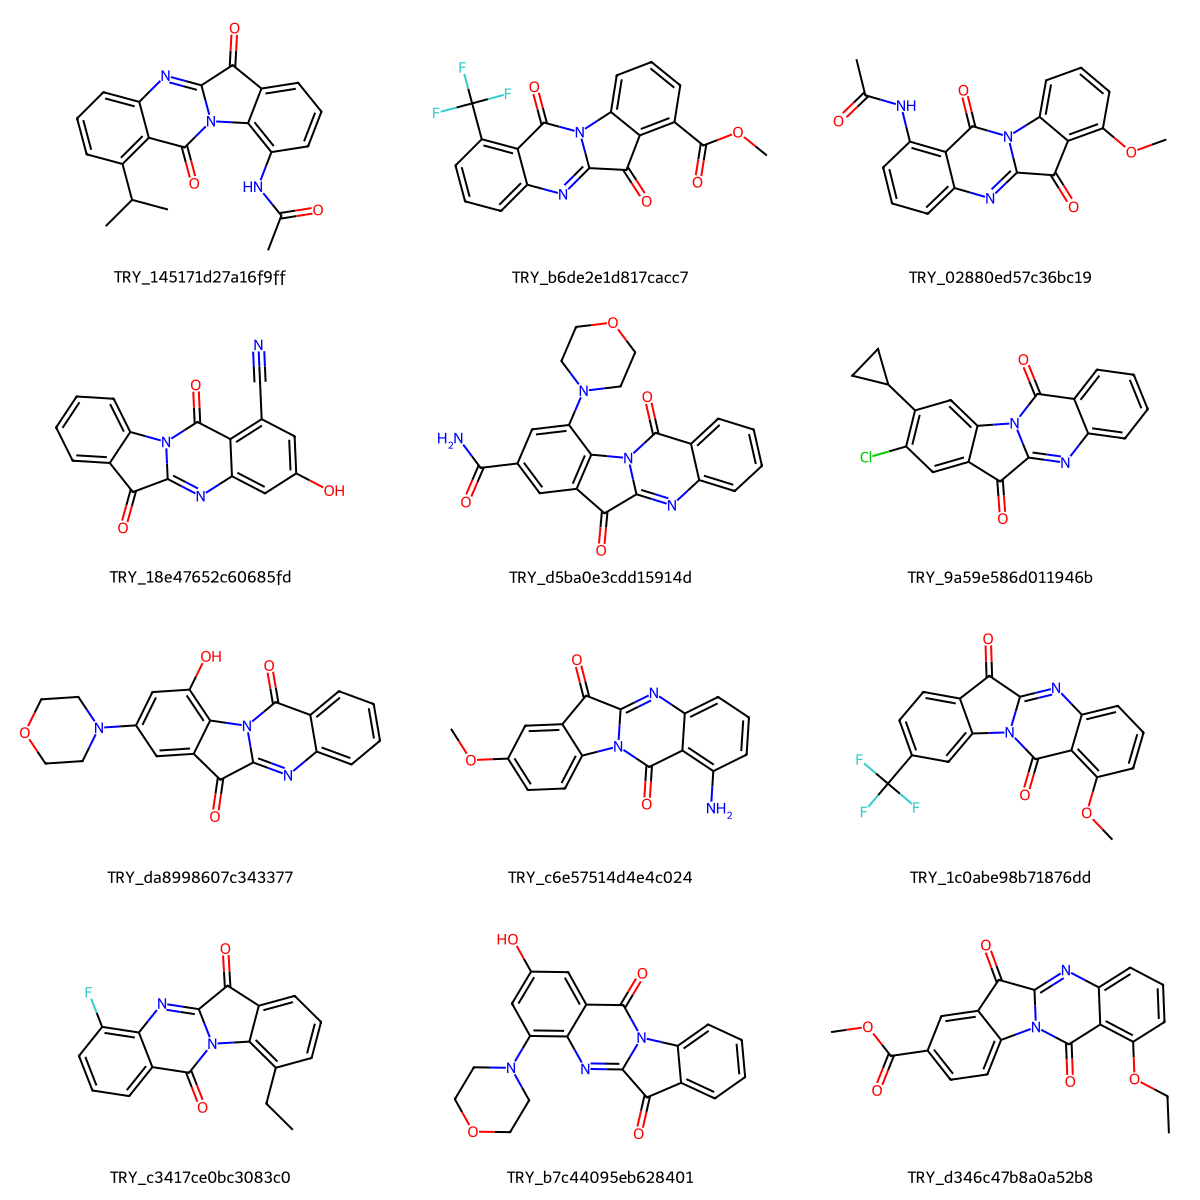

In [4]:
sample = clean.sample(n=12, random_state=42)
display(Draw.MolsToGridImage(
    [Chem.MolFromSmiles(s) for s in sample["SMILES"]],
    legends=sample["Analog_ID"].tolist(),
    molsPerRow=3,
    subImgSize=(400, 300)
))